# Módulo 4: Aprendizaje Automático (Machine Learning)
## Semana 2 - Clase 5: Taller Comparativo de Clasificadores

En la clase anterior utilizamos **Regresión Logística** para predecir categorías. Sin embargo, en la Inteligencia Artificial existe el teorema del *"No Free Lunch"* (No hay almuerzo gratis), que dicta que **ningún algoritmo es perfecto para todos los problemas**.

Hoy realizaremos un **Taller Comparativo** paso a paso. Usaremos un dataset químico de **Vinos** y enfrentaremos a 3 algoritmos con filosofías radicalmente distintas para ver cómo "piensan" y cómo toman decisiones:

1. **k-Nearest Neighbors (k-NN):** Filosofía basada en Similitud y Distancia (Geometría).
2. **Árboles de Decisión:** Filosofía basada en Reglas Lógicas (If-Then).
3. **Naive Bayes:** Filosofía basada en Probabilidad Teórica.

---
## **Paso 1: Extracción y Exploración de Datos**

Utilizaremos el famoso dataset *Wine Quality* incluido en `scikit-learn`. El objetivo es predecir de qué **cultivo (Clase 0, 1 o 2)** proviene un vino basándonos en sus componentes químicos.

### Diccionario de Datos (Traducción al Español)
Dado que las bases de datos originales están en inglés, aquí detallamos el propósito de cada columna para entender la química del vino:
- **Alcohol:** Grado alcohólico del vino.
- **Acido_Malico (Malic Acid):** Un ácido natural del vino que da sabor agrio.
- **Ceniza (Ash):** Cantidad de material inorgánico restante tras la evaporación.
- **Alcalinidad_Ceniza (Alcalinity of Ash):** Medida de qué tan alcalina es la ceniza.
- **Magnesio (Magnesium):** Mineral presente en el vino.
- **Fenoles_Totales (Total Phenols):** Compuestos químicos que afectan el sabor y color.
- **Flavonoides (Flavanoids):** Antioxidantes naturales en la uva.
- **Fenoles_No_Flavonoides:** Otro tipo de compuesto aromático.
- **Proantocianidinas:** Taninos que dan estructura y astringencia al vino.
- **Intensidad_Color:** Qué tan oscuro es el vino.
- **Matiz (Hue):** Tonalidad del color del vino.
- **OD280_OD315:** Medida de dilución del vino (prueba de pureza de proteínas).
- **Prolina (Proline):** Un aminoácido principal presente en la uva.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ocultar advertencias para una clase más limpia
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine

datos_vino = load_wine()
X = pd.DataFrame(datos_vino.data, columns=datos_vino.feature_names)
y = pd.Series(datos_vino.target, name="Clase_de_Vino")

# Mapeo para traducir las columnas al español y facilitar la comprensión
mapeo_columnas = {
    'alcohol': 'Alcohol',
    'malic_acid': 'Acido_Malico',
    'ash': 'Ceniza',
    'alcalinity_of_ash': 'Alcalinidad_Ceniza',
    'magnesium': 'Magnesio',
    'total_phenols': 'Fenoles_Totales',
    'flavanoids': 'Flavonoides',
    'nonflavanoid_phenols': 'Fenoles_No_Flavonoides',
    'proanthocyanins': 'Proantocianidinas',
    'color_intensity': 'Intensidad_Color',
    'hue': 'Matiz',
    'od280/od315_of_diluted_wines': 'OD280_OD315',
    'proline': 'Prolina'
}

X.rename(columns=mapeo_columnas, inplace=True)
print("Datos cargados y columnas traducidas al español exitosamente.")

Datos cargados y columnas traducidas al español exitosamente.


Veamos los primeros 5 registros para comprobar la traducción y los datos.

In [ ]:
display(X.head())

,Alcohol,Acido_Malico,Ceniza,Alcalinidad_Ceniza,Magnesio,Fenoles_Totales,Flavonoides,Fenoles_No_Flavonoides,Proantocianidinas,Intensidad_Color,Matiz,OD280_OD315,Prolina
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Ahora veamos cómo están distribuidas las clases (lo que queremos predecir). ¿Están balanceadas?

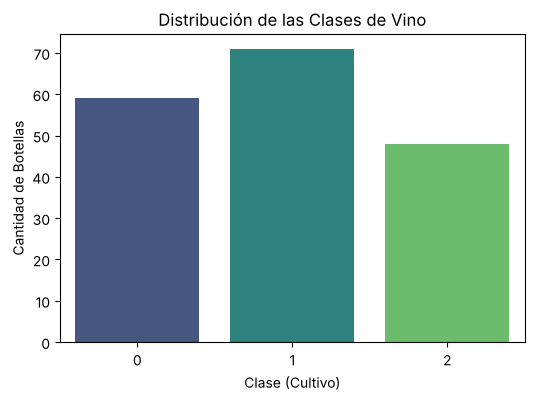

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x=y, palette='viridis')
plt.title('Distribución de las Clases de Vino')
plt.xlabel('Clase (Cultivo)')
plt.ylabel('Cantidad de Botellas')
plt.show()

---
## **Paso 2: Separación de Datos (Train/Test Split)**

Como siempre, debemos ocultarle una parte de los datos a nuestros algoritmos para poder examinarlos al final de la clase.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
print(f"Datos para entrenar (aprender): {X_train.shape[0]} botellas.")
print(f"Datos para evaluar (examen): {X_test.shape[0]} botellas.")

Datos para entrenar (aprender): 124 botellas.
Datos para evaluar (examen): 54 botellas.


---
## **Paso 3: Modelo 1 - k-Nearest Neighbors (k-NN)**

**Filosofía:** "Dime con quién andas y te diré quién eres".
El algoritmo de los $k$ vecinos más cercanos no calcula fórmulas. Cuando llega un vino nuevo, simplemente mide la distancia geométrica hacia los otros vinos. Si le decimos que $k=5$, buscará los 5 vinos más parecidos y hará una votación.

**EL PELIGRO:** Como usa distancias matemáticas, las columnas con números grandes arruinarán el cálculo frente a columnas con números pequeños.

**Demostración del problema:** Observemos el tamaño de los números en nuestros datos crudos.

In [ ]:
print("Valores máximos sin escalar:")
display(X_train[['Alcohol', 'Magnesio', 'Prolina']].max())

Valores máximos sin escalar:


Alcohol       14.83
Magnesio     162.00
Prolina     1515.00
dtype: float64

¡La Prolina llega a más de 1600 mientras el Alcohol apenas a 14! k-NN creerá falsamente que la Prolina es más importante.
**Solución Obligatoria:** Estandarizar (Escalar) los datos.

In [ ]:
from sklearn.preprocessing import StandardScaler

# 1. Instanciamos el escalador
scaler = StandardScaler()

# 2. Escalamos los datos de entrenamiento y de prueba
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

print("¡Datos escalados exitosamente! Ahora todas las columnas tienen la misma importancia geométrica.")

¡Datos escalados exitosamente! Ahora todas las columnas tienen la misma importancia geométrica.


Ahora sí, entrenemos a nuestro clasificador k-NN y veamos qué tan exacto es.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 3. Instanciar y Entrenar
knn = KNeighborsClassifier(n_neighbors=5) # Elegimos buscar a los 5 vecinos más cercanos
knn.fit(X_train_esc, y_train)

# 4. Predecir y Evaluar
pred_knn = knn.predict(X_test_esc)
acc_knn = accuracy_score(y_test, pred_knn)
print(f"Exactitud de k-NN: {acc_knn * 100:.2f}%")

Exactitud de k-NN: 94.44%


---
## **Paso 4: Modelo 2 - Árboles de Decisión**

**Filosofía:** El juego de "Adivina Quién?".
Un Árbol de Decisión no usa distancias, usa **reglas lógicas**. Buscará la columna química que mejor parta los datos en grupos puros (bajando la *Entropía* o impureza de *Gini*).

*Nota Docente: ¡Los árboles NO necesitan que escalemos los datos! A una regla If-Then no le importa el tamaño del número.*

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# 1. Instanciar y Entrenar
# max_depth=3 significa que solo le permitiremos hacer 3 niveles de preguntas para evitar que se "memorice" los datos (Overfitting)
arbol = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol.fit(X_train, y_train) # Usamos los datos originales (en español) sin escalar

# 2. Predecir y Evaluar
pred_arbol = arbol.predict(X_test)
acc_arbol = accuracy_score(y_test, pred_arbol)
print(f"Exactitud del Árbol de Decisión: {acc_arbol * 100:.2f}%")

Exactitud del Árbol de Decisión: 96.30%


**Visualización del Árbol:**
La mayor ventaja de un árbol es que podemos imprimir su "cerebro" y leer exactamente qué decisiones tomó. Fíjese cómo las columnas traducidas al español aparecen directamente en el gráfico.

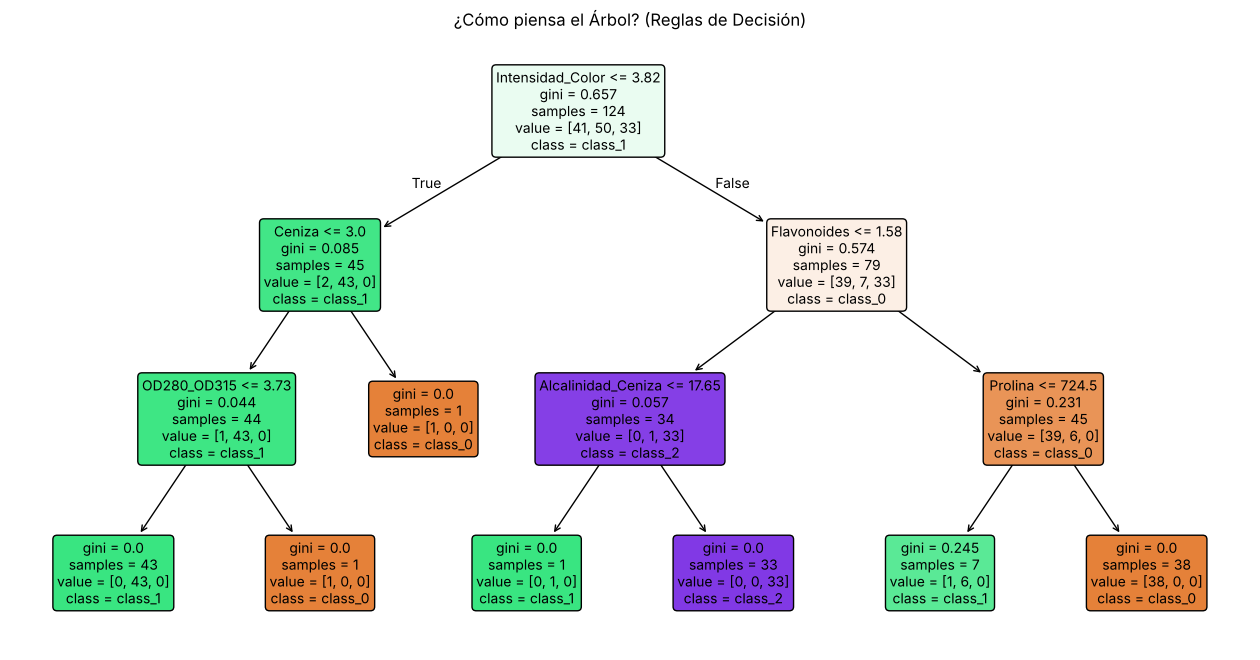

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))
plot_tree(arbol,
          feature_names=X.columns, # Usamos nuestras nuevas columnas en español
          class_names=datos_vino.target_names,
          filled=True,
          rounded=True,
          fontsize=10)
plt.title('¿Cómo piensa el Árbol? (Reglas de Decisión)')
plt.show()

---
## **Paso 5: Modelo 3 - Naive Bayes**

**Filosofía:** Probabilidad Pura (Teorema de Bayes).
Se llama "Ingenuo" (*Naive*) porque asume que el nivel de Alcohol no tiene relación matemática con el Magnesio. En la realidad esto es falso, pero asumir esa ingenuidad hace que el cálculo de probabilidades sea **extremadamente rápido**.

In [ ]:
from sklearn.naive_bayes import GaussianNB

# 1. Instanciar y Entrenar
bayes = GaussianNB()
bayes.fit(X_train, y_train)

# 2. Predecir y Evaluar
pred_bayes = bayes.predict(X_test)
acc_bayes = accuracy_score(y_test, pred_bayes)
print(f"Exactitud de Naive Bayes: {acc_bayes * 100:.2f}%")

Exactitud de Naive Bayes: 100.00%


---
## **Paso 6: Comparación de Fronteras de Decisión (Visualización de los Datos Reales)**

Para entender verdaderamente cómo funciona cada algoritmo (y para que sea fácil de enseñar a la clase), **reduciremos nuestro dataset a solo 2 columnas** (`Alcohol` y `Flavonoides`) para poder graficarlo en un plano de 2 dimensiones (X e Y).

Esto nos permitirá ver visualmente cómo cada algoritmo "corta" (Frontera de Decisión) la gráfica para clasificar los vinos.

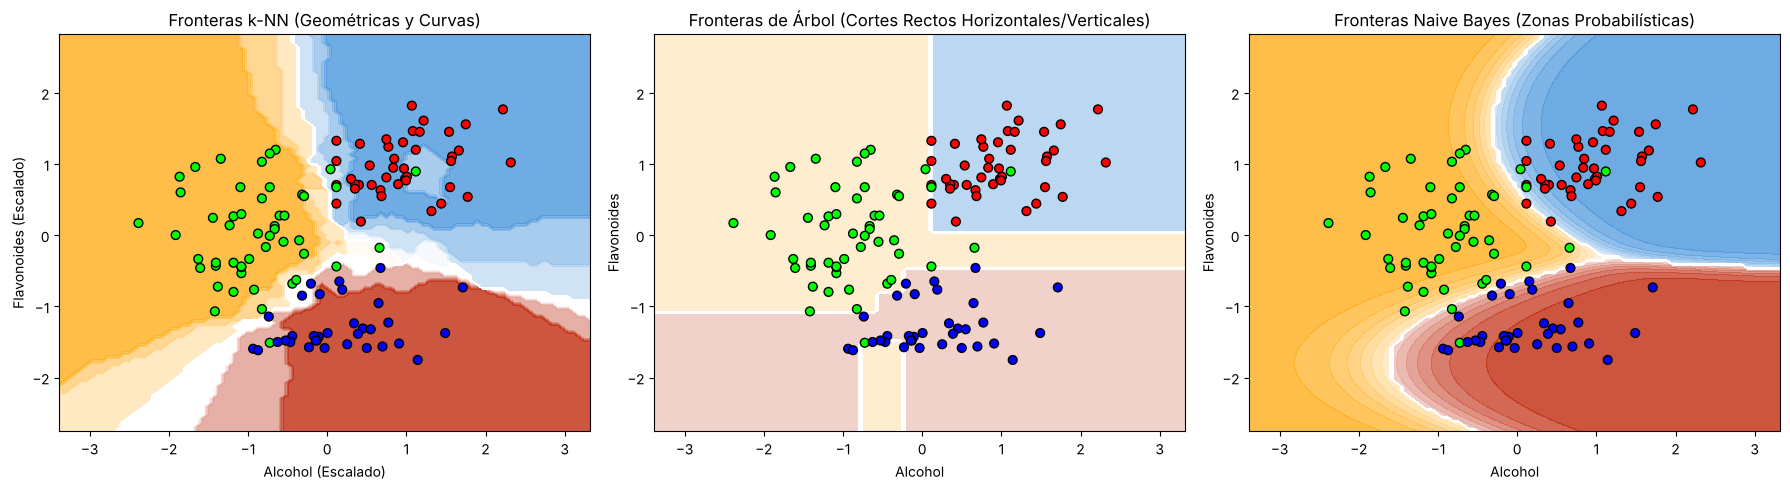

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

# Para poder graficar en 2D, elegimos solo 2 características.
X_2D = X_train[['Alcohol', 'Flavonoides']]

# k-NN sufre si no lo escalamos, así que escalamos estas 2 columnas
scaler_2d = StandardScaler()
X_2D_esc = scaler_2d.fit_transform(X_2D)

# Entrenamos 3 modelos "miniaturas" que solo ven estas 2 columnas
knn_2d = KNeighborsClassifier(n_neighbors=5).fit(X_2D_esc, y_train)
arbol_2d = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_2D_esc, y_train)
bayes_2d = GaussianNB().fit(X_2D_esc, y_train)

# Configuración del gráfico (3 paneles)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

# --- 1. Panel de k-NN ---
DecisionBoundaryDisplay.from_estimator(knn_2d, X_2D_esc, cmap=cmap_light, ax=ax1, alpha=0.8)
ax1.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax1.set_title("Fronteras k-NN (Geométricas y Curvas)")
ax1.set_xlabel('Alcohol (Escalado)')
ax1.set_ylabel('Flavonoides (Escalado)')

# --- 2. Panel de Árbol de Decisión ---
DecisionBoundaryDisplay.from_estimator(arbol_2d, X_2D_esc, cmap=cmap_light, ax=ax2, alpha=0.8)
ax2.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax2.set_title("Fronteras de Árbol (Cortes Rectos Horizontales/Verticales)")
ax2.set_xlabel('Alcohol')
ax2.set_ylabel('Flavonoides')

# --- 3. Panel de Naive Bayes ---
DecisionBoundaryDisplay.from_estimator(bayes_2d, X_2D_esc, cmap=cmap_light, ax=ax3, alpha=0.8)
ax3.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax3.set_title("Fronteras Naive Bayes (Zonas Probabilísticas)")
ax3.set_xlabel('Alcohol')
ax3.set_ylabel('Flavonoides')

plt.tight_layout()
plt.show()

Observe las gráficas de arriba junto a sus alumnos:
* **k-NN** genera áreas curvas de decisión como si trazara contornos geográficos intentando rodear a los grupitos.
* **Árbol de Decisión** JAMÁS genera curvas. Todo son cortes perfectamente rectos horizontales y verticales, porque son reglas de "Mayor que" y "Menor que".
* **Naive Bayes** genera zonas amplias y suavizadas dictadas por las campanas de distribución probabilística.

---
## **Paso 7: Comparación de Desempeño y Conclusión de Taller**

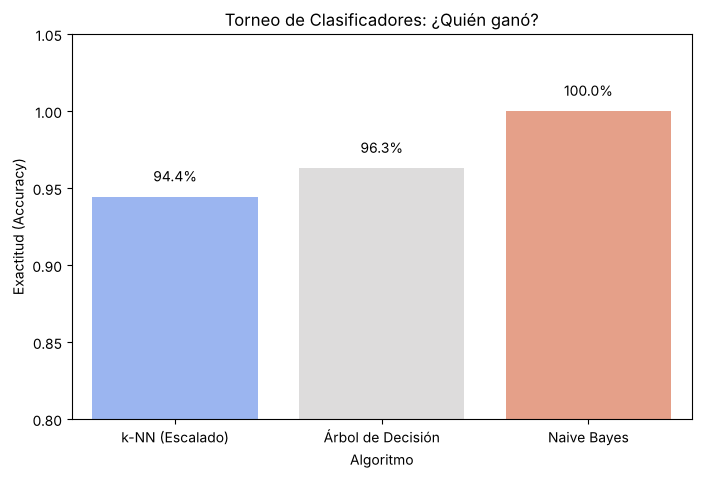

In [ ]:
# Crear un DataFrame con los resultados
resultados = pd.DataFrame({
    'Algoritmo': ['k-NN (Escalado)', 'Árbol de Decisión', 'Naive Bayes'],
    'Exactitud (Accuracy)': [acc_knn, acc_arbol, acc_bayes]
})

# Graficar comparativa
plt.figure(figsize=(8,5))
sns.barplot(x='Algoritmo', y='Exactitud (Accuracy)', data=resultados, palette='coolwarm')
plt.title('Torneo de Clasificadores: ¿Quién ganó?')
plt.ylim(0.8, 1.05) # Enfocar el gráfico en la parte alta para notar las diferencias

# Agregar etiquetas de porcentaje en las barras
for index, row in resultados.iterrows():
    plt.text(index, row['Exactitud (Accuracy)'] + 0.01, f"{row['Exactitud (Accuracy)']*100:.1f}%", color='black', ha="center")

plt.show()

### **Conclusión del Docente:**
En este dataset en particular, los resultados pueden ser muy parejos. Sin embargo, en el mundo real:
* Si el cliente necesita saber **POR QUÉ** se tomó una decisión (ej. Auditoría Médica o Legal), el **Árbol de Decisión** es el único que da explicaciones visuales.
* Si el dataset fuera de 5 millones de correos electrónicos (texto gigante), **k-NN** colapsaría y **Naive Bayes** lo resolvería en segundos.
* Si las fronteras de separación son muy complejas y curvas, **k-NN** suele adaptarse maravillosamente.

---
## **Paso 8: Mapa de Calor de Correlaciones y Tercera Característica Más Representativa TAREA 2**

Hasta ahora elegimos `Alcohol` y `Flavonoides` a mano. Ahora usaremos una **matriz de correlación** para ver qué variables se relacionan más con la clase de vino y así encontrar una **tercera característica** representativa.

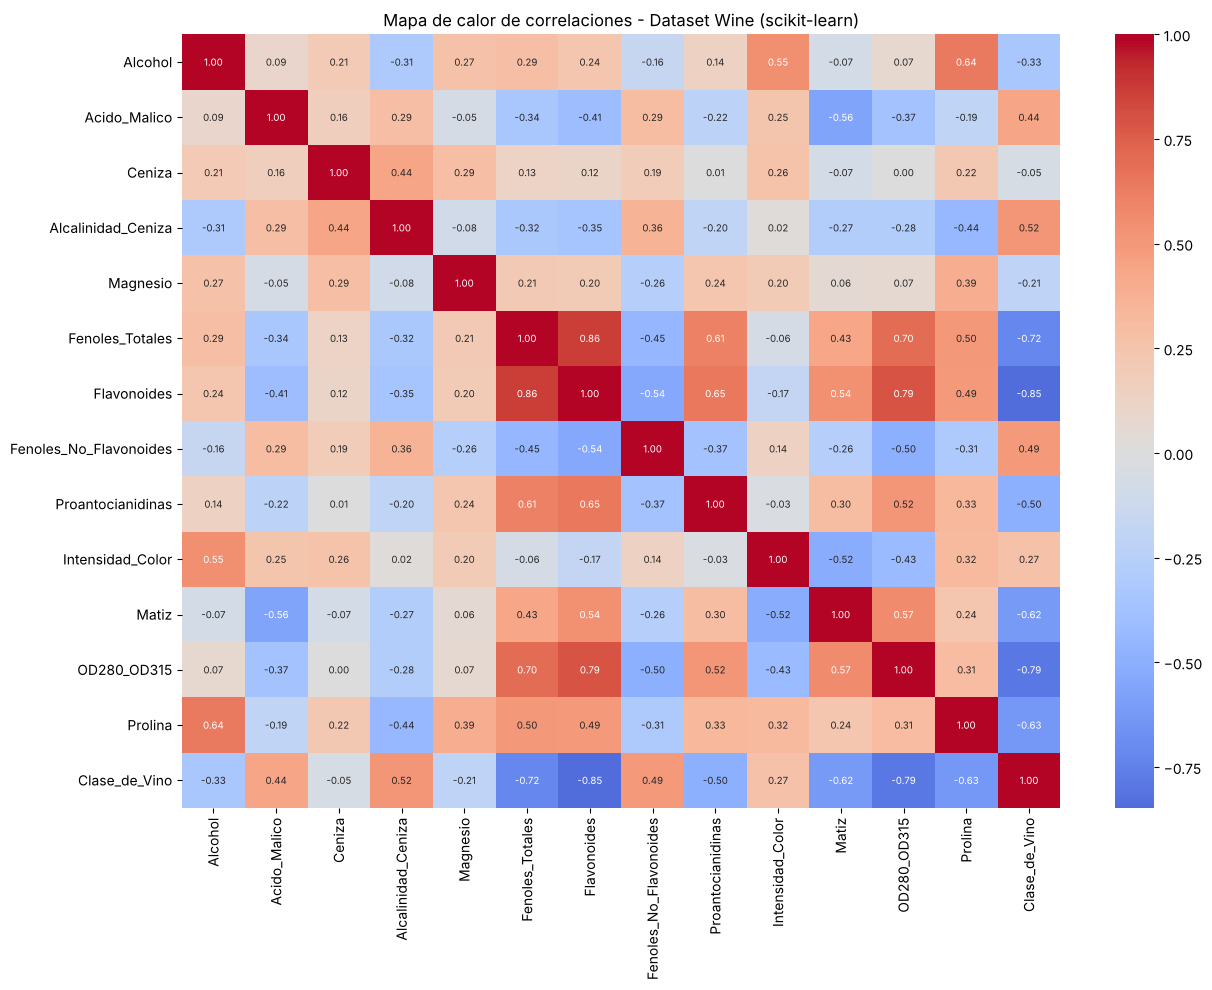

In [ ]:
# Matriz de correlación (variables + clase de vino)
datos_completos = pd.concat([X, y], axis=1)
corr = datos_completos.corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Mapa de calor de correlaciones - Dataset Wine (scikit-learn)")
plt.tight_layout()
plt.show()

In [ ]:
# Ranking de variables según su correlación (en valor absoluto) con la clase
corr_clase = corr["Clase_de_Vino"].drop("Clase_de_Vino")
ranking = corr_clase.abs().sort_values(ascending=False)
display(pd.DataFrame({"Correlación con la clase": corr_clase[ranking.index].round(3),
                      "|Correlación|": ranking.round(3)}))

# Tercera característica: la mejor correlacionada con la clase, distinta de Alcohol y Flavonoides
candidatas = ranking.drop(["Alcohol", "Flavonoides"])
tercera = candidatas.index[0]
print(f"\nTercera característica más representativa: {tercera} (correlación con la clase = {corr_clase[tercera]:.3f})")
print(f"Correlación de {tercera} con Flavonoides: {corr.loc[tercera, 'Flavonoides']:.3f}")
print(f"Correlación de {tercera} con Alcohol:     {corr.loc[tercera, 'Alcohol']:.3f}")


Tercera característica más representativa: OD280_OD315 (correlación con la clase = -0.788)
Correlación de OD280_OD315 con Flavonoides: 0.787
Correlación de OD280_OD315 con Alcohol:     0.072


,Correlación con la clase,|Correlación|
Flavonoides,-0.847,0.847
OD280_OD315,-0.788,0.788
Fenoles_Totales,-0.719,0.719
Prolina,-0.634,0.634
Matiz,-0.617,0.617
Alcalinidad_Ceniza,0.518,0.518
Proantocianidinas,-0.499,0.499
Fenoles_No_Flavonoides,0.489,0.489
Acido_Malico,0.438,0.438
Alcohol,-0.328,0.328


**Interpretación:** `Flavonoides` es la variable más ligada a la clase, y la mejor candidata para acompañarla es `OD280_OD315`. Pero ojo: ambas están muy correlacionadas entre sí (~0.79), es decir, **son parcialmente redundantes**. En cambio, `Alcohol` casi no se relaciona con `OD280_OD315` (~0.07), así que esa pareja aporta información complementaria.

---
## **Paso 9: Gráfico de Pares (Alcohol, Flavonoides y la tercera característica)**

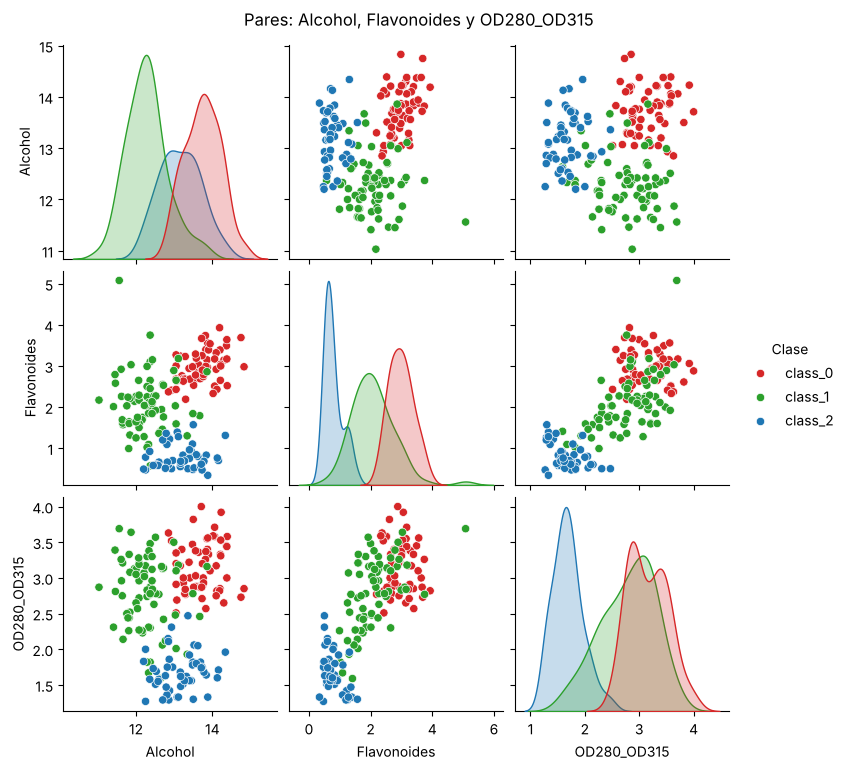

In [ ]:
caracteristicas = ["Alcohol", "Flavonoides", tercera]
colores = ["#d62728", "#2ca02c", "#1f77b4"]
nombres_clase = list(datos_vino.target_names)

df_pares = X[caracteristicas].copy()
df_pares["Clase"] = y.map(dict(enumerate(nombres_clase)))

g = sns.pairplot(df_pares, hue="Clase", palette=dict(zip(nombres_clase, colores)), diag_kind="kde")
g.fig.suptitle(f"Pares: Alcohol, Flavonoides y {tercera}", y=1.02)
plt.show()

**Qué observar:** En `Alcohol` vs `Flavonoides` las 3 clases forman nubes bastante separadas. En `Flavonoides` vs `OD280_OD315` la clase 2 (azul) se aísla muy bien, pero las clases 0 y 1 se traslapan porque las dos variables miden cosas parecidas.

---
## **Paso 10: Evaluación de k-NN, Árbol de Decisión y Naive Bayes sobre estas variables**

Evaluamos cada modelo con las 3 variables y con cada par de variables, usando el mismo *split* de antes (**test**) y además **validación cruzada de 5 folds** (más confiable con tan pocos datos de prueba).

In [ ]:
from itertools import combinations
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold

def crear_modelos():
    return {
        "k-NN (k=5)":      make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
        "Árbol (prof. 4)": DecisionTreeClassifier(max_depth=4, random_state=42),
        "Naive Bayes":     make_pipeline(StandardScaler(), GaussianNB()),
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pares_vars = list(combinations(caracteristicas, 2))

filas = []
for nombre in crear_modelos():
    fila = {"Modelo": nombre}
    m = crear_modelos()[nombre].fit(X_train[caracteristicas], y_train)
    fila["Test (3 variables)"] = m.score(X_test[caracteristicas], y_test)
    fila["CV (3 variables)"] = cross_val_score(crear_modelos()[nombre], X[caracteristicas], y, cv=cv).mean()
    for a, b in pares_vars:
        m2 = crear_modelos()[nombre].fit(X_train[[a, b]], y_train)
        fila[f"Test {a}+{b}"] = m2.score(X_test[[a, b]], y_test)
        fila[f"CV {a}+{b}"] = cross_val_score(crear_modelos()[nombre], X[[a, b]], y, cv=cv).mean()
    filas.append(fila)

tabla_eval = pd.DataFrame(filas).set_index("Modelo")
display(tabla_eval.round(3).T)

Modelo,k-NN (k=5),Árbol (prof. 4),Naive Bayes
Test (3 variables),0.870,0.852,0.889
CV (3 variables),0.910,0.899,0.921
Test Alcohol+Flavonoides,0.889,0.889,0.907
CV Alcohol+Flavonoides,0.921,0.899,0.921
Test Alcohol+OD280_OD315,0.833,0.833,0.815
CV Alcohol+OD280_OD315,0.877,0.854,0.882
Test Flavonoides+OD280_OD315,0.926,0.833,0.889
CV Flavonoides+OD280_OD315,0.837,0.815,0.848


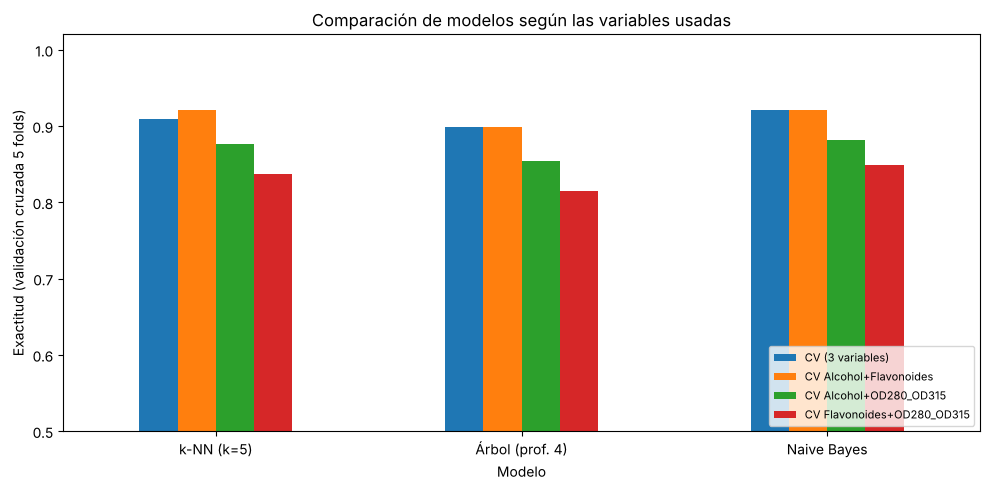

In [ ]:
columnas_cv = [c for c in tabla_eval.columns if c.startswith("CV")]
ax = tabla_eval[columnas_cv].plot.bar(figsize=(10, 5), rot=0)
ax.set_ylabel("Exactitud (validación cruzada 5 folds)")
ax.set_ylim(0.5, 1.02)
ax.set_title("Comparación de modelos según las variables usadas")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

---
## **Paso 11: Fronteras de Decisión - ¿Cuál modelo se ve más claro?**

Dibujamos las fronteras de cada modelo (filas) para cada par de variables (columnas). Los colores de fondo y de los puntos coinciden: **rojo = clase 0, verde = clase 1, azul = clase 2**. Los puntos con borde negro son los de prueba.

Para medir la "claridad" de forma objetiva contamos cuántas **regiones separadas** forma cada frontera: lo ideal son 3 (una por clase). Más regiones = frontera fragmentada.

Regiones por frontera (menos = más clara; ideal = 3):


,Alcohol+Flavonoides,Alcohol+OD280_OD315,Flavonoides+OD280_OD315
Naive Bayes,3,3,3
k-NN (k=5),3,4,13
Árbol (prof. 4),4,5,4


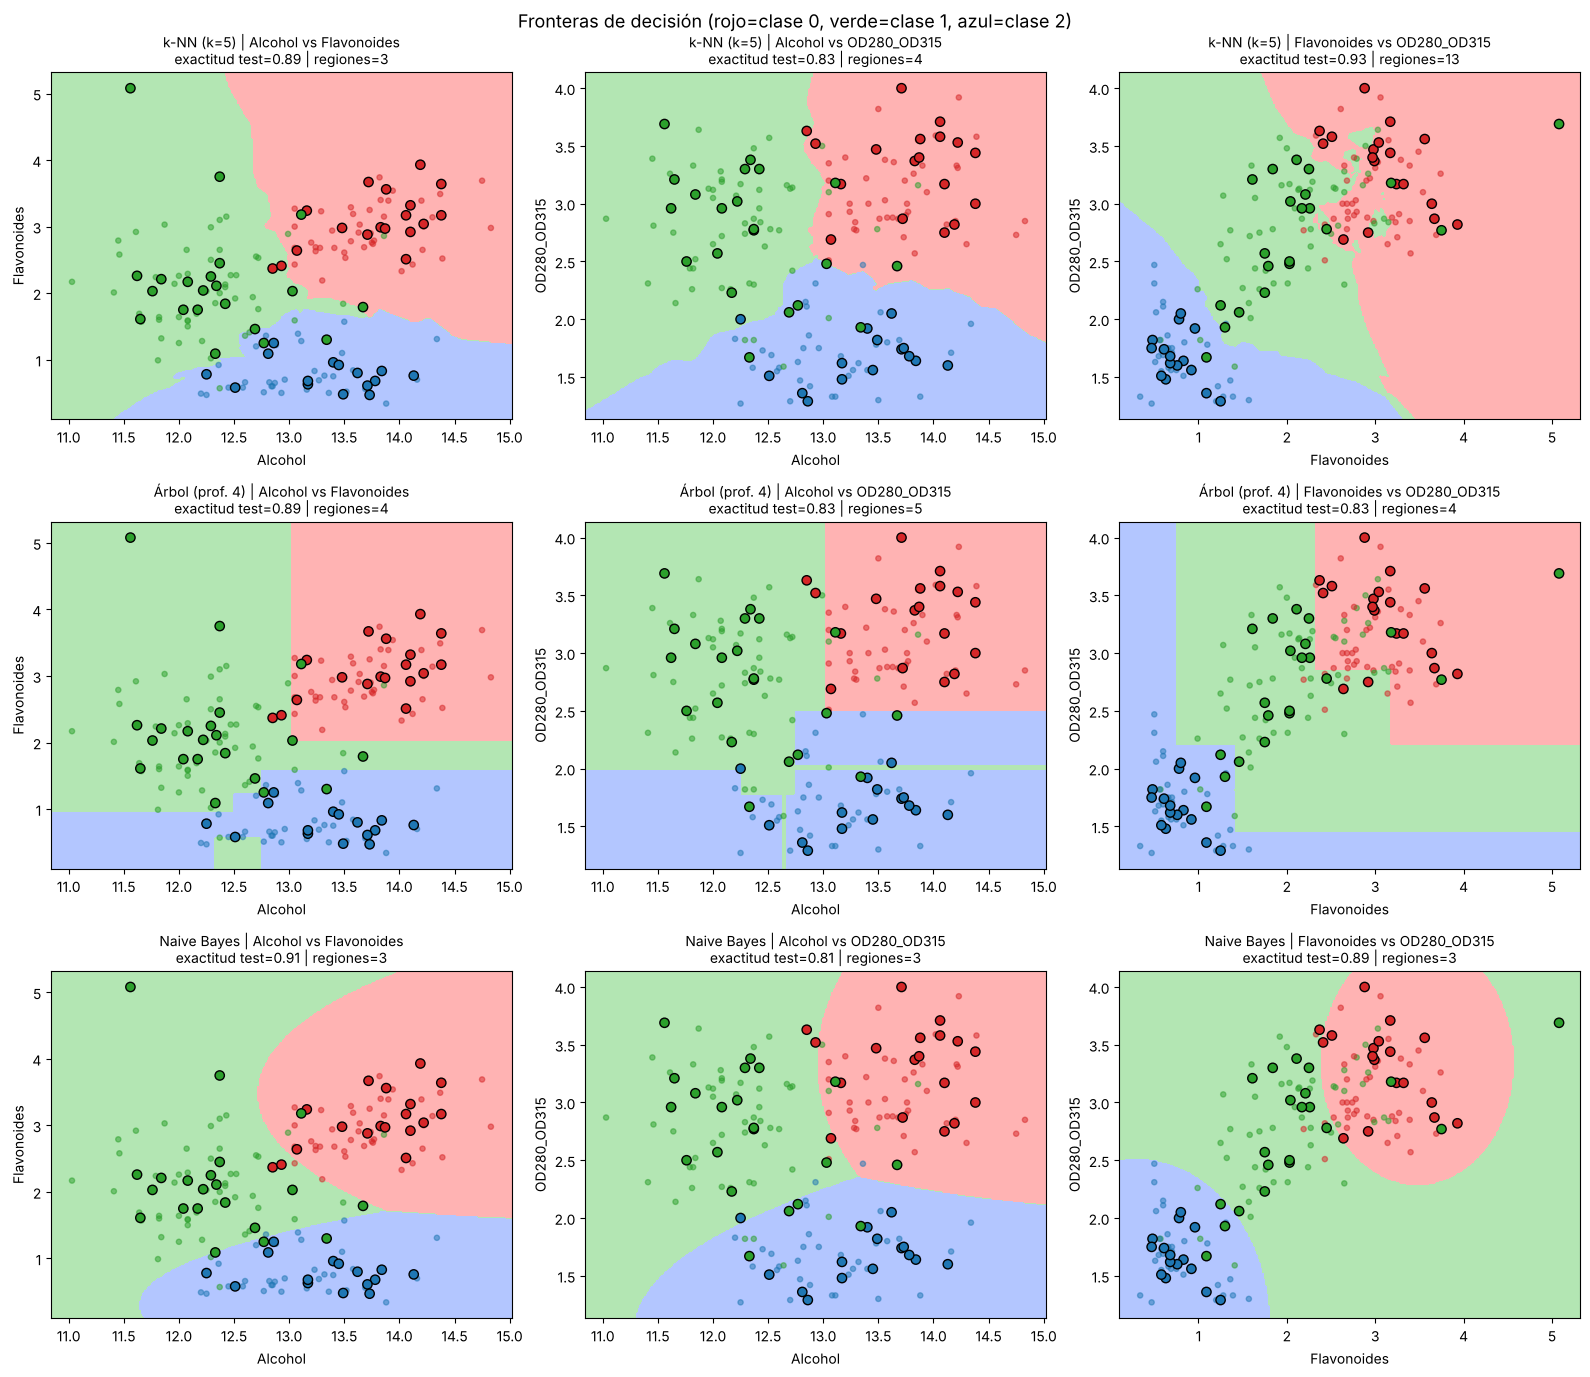

In [ ]:
from scipy import ndimage

cmap_fondo = ListedColormap(["#FFB3B3", "#B3E6B3", "#B3C6FF"])
cmap_puntos = ListedColormap(colores)
fragmentos = {}

fig, axes = plt.subplots(3, 3, figsize=(16, 14))
for i, nombre in enumerate(crear_modelos()):
    for j, (a, b) in enumerate(pares_vars):
        ax = axes[i, j]
        modelo = crear_modelos()[nombre].fit(X_train[[a, b]], y_train)

        # Malla para pintar las regiones de predicción
        minimo = X[[a, b]].min().values
        maximo = X[[a, b]].max().values
        margen = (maximo - minimo) * 0.05
        xx, yy = np.meshgrid(np.linspace(minimo[0] - margen[0], maximo[0] + margen[0], 300),
                             np.linspace(minimo[1] - margen[1], maximo[1] + margen[1], 300))
        malla = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=[a, b])
        Z = modelo.predict(malla).reshape(xx.shape)

        n_regiones = sum(ndimage.label(Z == k)[1] for k in range(3))
        fragmentos[(nombre, f"{a}+{b}")] = n_regiones

        ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], cmap=cmap_fondo)
        ax.scatter(X_train[a], X_train[b], c=y_train, cmap=cmap_puntos, s=14, alpha=0.5)
        ax.scatter(X_test[a], X_test[b], c=y_test, cmap=cmap_puntos, edgecolor="k", s=45)
        ax.set_xlabel(a); ax.set_ylabel(b)
        ax.set_title(f"{nombre} | {a} vs {b}\nexactitud test={modelo.score(X_test[[a, b]], y_test):.2f} | regiones={n_regiones}", fontsize=10)

plt.suptitle("Fronteras de decisión (rojo=clase 0, verde=clase 1, azul=clase 2)", fontsize=13)
plt.tight_layout()
plt.show()

print("Regiones por frontera (menos = más clara; ideal = 3):")
display(pd.Series(fragmentos).unstack())

### **Conclusión del Paso 8 al 11**

* **Tercera característica:** `OD280_OD315` es la más relacionada con la clase después de `Flavonoides`, aunque es parcialmente redundante con ella (correlación ~0.79).
* **Exactitud:** con validación cruzada, k-NN y Naive Bayes empatan (~0.92) usando `Alcohol + Flavonoides`; el Árbol queda un poco por debajo (~0.90). Con tan pocos datos de prueba, la diferencia es de 1 a 3 botellas, así que **no es concluyente**.
* **Claridad gráfica:** **Naive Bayes** ofrece la representación más clara: 3 regiones suaves y continuas (una por clase) en los tres pares de variables. El **Árbol** genera cortes rectangulares con islas pequeñas (4-5 regiones) y **k-NN** se fragmenta mucho con `Flavonoides + OD280_OD315` (13 regiones, señal de sobreajuste).
* **Mejor combinación para graficar:** `Alcohol` vs `Flavonoides`, ya que las clases se ven separadas y la información de las dos variables es complementaria.